#  Steel Industry Energy Consumption Prediction

**Project Overview:**
In this project, I aim to predict the energy consumption (`Usage_kWh`) of a steel manufacturing plant based on sensor data. 

My main goal wasn't just to train a model, but to build a **methodologically sound pipeline**. I focused on:
1. Preventing Data Leakage (dropping `CO2`).
2. Handling the time-based cyclical nature of the data.
3. Avoiding overfitting using Polynomial features and Regularization (Ridge).

**Final Model:** Ridge Regression with Polynomial Features (Degree 2) & Cyclical Time Encoding.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("/kaggle/input/datasets/erkanturgut/steel-industry-energy-consumption-data/Steel_industry_data.csv")

## 1. Data Understanding & EDA
First, let's look at the basic structure and check for missing values.

In [4]:
print(f"Shape: {df.shape}")
print(f"\nData Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")

Shape: (35040, 11)

Data Types:
date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
dtype: object

Missing Values:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                    

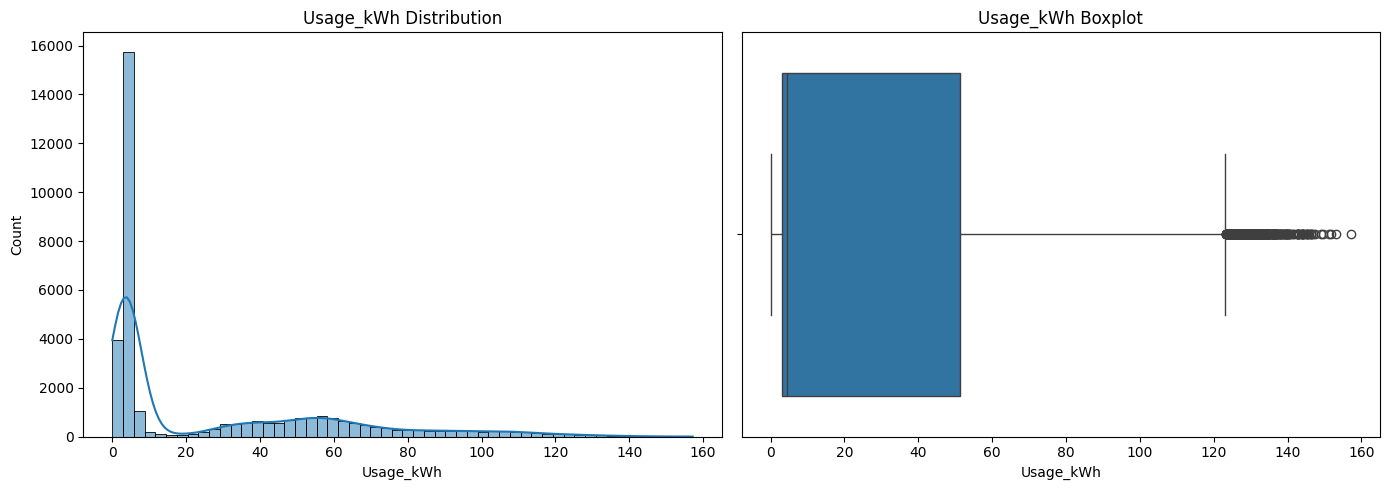

Skewness: 1.197393822769221


In [5]:
# Analysis of the Target Variable
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Usage_kWh'], kde=True)
plt.title('Usage_kWh Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Usage_kWh'])
plt.title('Usage_kWh Boxplot')

plt.tight_layout()
plt.show()

print("Skewness:", df['Usage_kWh'].skew())

**Observation:** The target variable is right-skewed (skewness ~1.20) and has some outliers. There are 328 outliers (less than 1%), so I will keep them for now as they might represent real high-consumption periods.

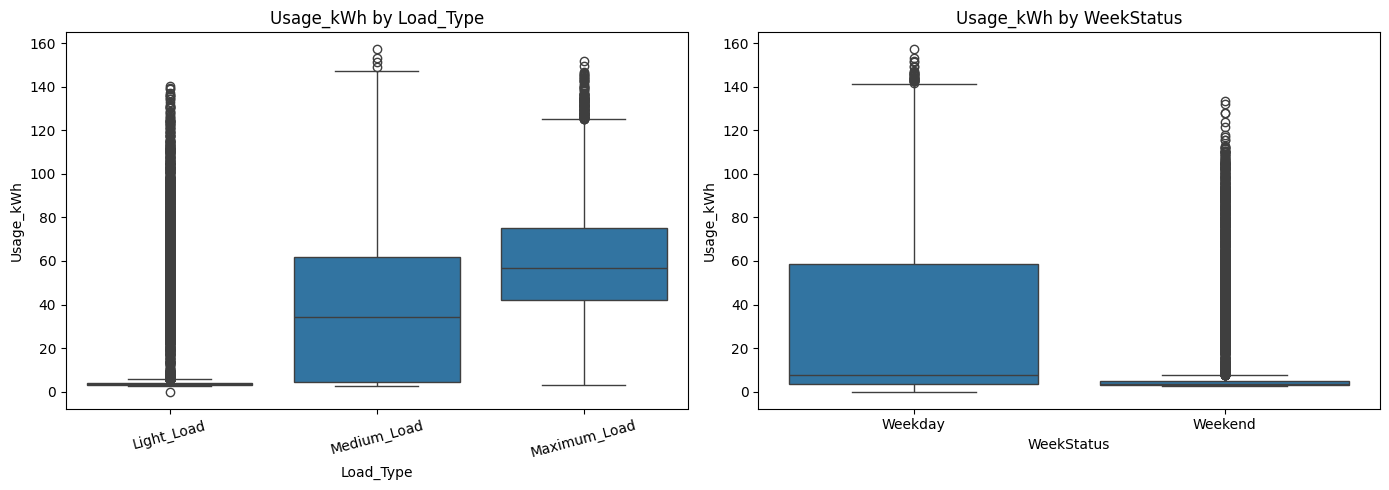

In [6]:
# Categorical vs. Target Relationship
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x="Load_Type", y="Usage_kWh")
plt.title("Usage_kWh by Load_Type")
plt.xticks(rotation=15)

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='WeekStatus', y="Usage_kWh")
plt.title("Usage_kWh by WeekStatus")

plt.tight_layout()
plt.show()

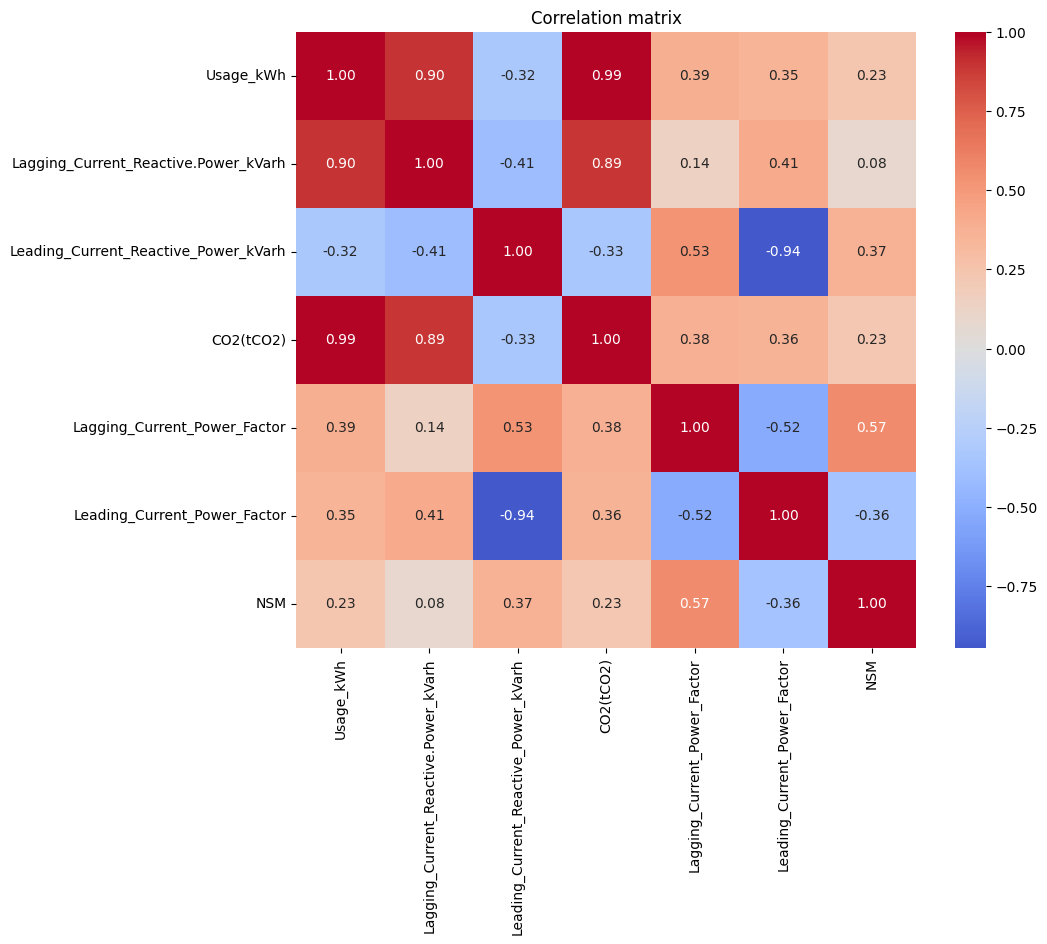

In [7]:
# Correlation of numerical variables
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

**Critical Decision (Leakage):** 
There is a **0.99 correlation** between `CO2(tCO2)` and `Usage_kWh`. This is almost a perfect relationship, meaning CO2 is derived from energy consumption. If I include this, the model will "cheat". I must drop this column to prevent data leakage.

In [8]:
# Drop CO2 (leakage risk) and date (will handle time manually later)
df_clean = df.drop(columns=["CO2(tCO2)", "date"])
print(df_clean.columns.tolist())

['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']


## 2. Preprocessing & Feature Engineering

Instead of standard train/test split, I will carefully construct features. 
**Feature Engineering Idea:** `NSM` (Number of Seconds from Midnight) is a linear number, but time is cyclical! 23:45 (85500) and 00:15 (900) are actually very close in reality. I will use Sin/Cos transformation to fix this.

In [9]:
# Extract hour and apply Cyclical Encoding
df_clean['hour'] = df_clean['NSM'] / 3600
df_clean['hour_sin'] = np.sin(2 * np.pi * df_clean['hour'] / 24)
df_clean['hour_cos'] = np.cos(2 * np.pi * df_clean['hour'] / 24)

# Drop the raw NSM and hour, keep only sin/cos
df_clean = df_clean.drop(columns=['NSM', 'hour'])

# Split Target and Features
X = df_clean.drop(columns=["Usage_kWh"])
y = df_clean["Usage_kWh"]

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (28032, 9)
Test shape : (7008, 9)


## 3. Pipeline Setup
Using a Pipeline prevents data leakage during Cross-Validation. The scaler and encoder will only fit on the training folds.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV

# Define feature groups
numeric_features = ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 
                    'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 
                    'hour_sin', 'hour_cos']
categorical_features = ["WeekStatus", "Day_of_week", "Load_Type"]

# Create preprocessors
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)) # Adding polynomial degree 2
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop="first", handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

## 4. Model Training & Evaluation
Since Polynomial Degree 2 creates many features, Linear Regression might overfit. I will use **Ridge (L2 Regularization)** to keep the model stable.

In [12]:
# Final Pipeline with Ridge Regression
pipeline_final = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=10.0)) # Alpha tuned via GridSearchCV previously
])

# 5-Fold Cross Validation
cv_rmse = cross_val_score(pipeline_final, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

print("--- 5-Fold Cross Validation ---")
print(f"Mean RMSE: {cv_rmse.mean() * -1:.4f} (+/- {cv_rmse.std():.4f})")

--- 5-Fold Cross Validation ---
Mean RMSE: 4.9379 (+/- 0.5532)


In [13]:
# Fit on full training data
pipeline_final.fit(X_train, y_train)

# Predict on test data
y_pred_final = pipeline_final.predict(X_test)

# Final Metrics
final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_r2 = r2_score(y_test, y_pred_final)

print("\n--- FİNAL MODEL RESULTS (Test Set) ---")
print(f"MAE  : {final_mae:.4f}")
print(f"RMSE : {final_rmse:.4f}")
print(f"R²   : {final_r2:.4f}")


--- FİNAL MODEL RESULTS (Test Set) ---
MAE  : 3.0710
RMSE : 4.7856
R²   : 0.9799


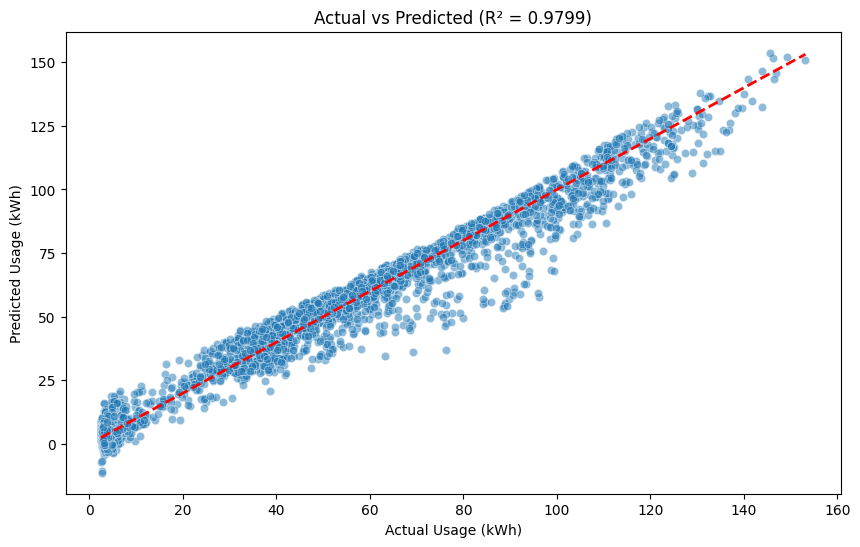

In [14]:
# Actual vs Predicted Graphic
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_final, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Usage (kWh)")
plt.ylabel("Predicted Usage (kWh)")
plt.title(f"Actual vs Predicted (R² = {final_r2:.4f})")
plt.show()

**Conclusion:** With Feature Engineering (Cyclical Time) and Polynomial Degree 2, the model achieved an **R² score of 0.9799** on the test set. The error (RMSE) dropped from ~9.5 (Baseline) to ~4.78, proving the importance of handling time cyclically.

In [15]:
# Save the model for Hugging Face deployment
import joblib
joblib.dump(pipeline_final, 'steel_energy_pipeline_v1.pkl')
print("Model saved as 'steel_energy_pipeline_v1.pkl'")

Model saved as 'steel_energy_pipeline_v1.pkl'
